In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [29]:
# Read in the data
timing_A = pd.read_csv('personKeyTimingA.txt', header=None, names=["time", "letter"])
timing_B = pd.read_csv('personKeyTimingB.txt', header=None, names=["time", "letter"])
email = pd.read_csv('email.txt', header=None, names=["time", "letter"])

timing_A.head()

,time,letter
0,7.5,T
1,15.4,h
2,23.3,e
3,28.7,r
4,36.5,e


##### **a.** Estimate $E[X]$ and $E[Y]$

In [30]:
# Compute the duration between each keystroke
timing_A['duration'] = timing_A['time'].diff()
timing_A.loc[0, 'duration'] = timing_A.loc[0, 'time'] # Because it's at the first row, there's no value to subtract. We need to set it's corresponding duration manully
timing_B['duration'] = timing_B['time'].diff()
timing_B.loc[0, 'duration'] = timing_B.loc[0, 'time'] # Because it's at the first row, there's no value to subtract. We need to set it's corresponding duration manully

timing_A.head()

,time,letter,duration
0,7.5,T,7.5
1,15.4,h,7.9
2,23.3,e,7.9
3,28.7,r,5.4
4,36.5,e,7.8


In [31]:
# Compute E[X] and E[Y]
E_X = timing_A['duration'].mean()
E_Y = timing_B['duration'].mean()

print(f"E[X] = {E_X}\nE[Y] = {E_Y}")

E[X] = 7.406725543478261
E[Y] = 8.030774456521739


##### **b.** Extimate $E[X^{2}]$ and $E[Y^{2}]$

In [32]:
# Compute the squared duration between each keystroke
timing_A['squared_duration'] = timing_A['duration'] ** 2
timing_B['squared_duration'] = timing_B['duration'] ** 2

timing_A.head()

,time,letter,duration,squared_duration
0,7.5,T,7.5,56.25
1,15.4,h,7.9,62.41
2,23.3,e,7.9,62.41
3,28.7,r,5.4,29.16
4,36.5,e,7.8,60.84


In [34]:
# Compute E[X^2] and E[Y^2]
E_X_squared = timing_A['squared_duration'].mean()
E_Y_squared = timing_B['squared_duration'].mean()

print(f"E[X^2] = {E_X_squared}\nE[Y^2] = {E_Y_squared}")

E[X^2] = 58.84015625000004
E[Y^2] = 68.17685461956508


##### **c.** Approximate X and Y as Normals and report both distributions

In [36]:
# Compute the variance of X and Y
Var_X = E_X_squared - E_X ** 2
Var_Y = E_Y_squared - E_Y ** 2

print(f"Var(X) = {Var_X}\nVar(Y) = {Var_Y}")

Var(X) = 3.980572973586696
Var(Y) = 3.6835162480430483


We can ontain that 

$
X \sim N(7.4067, 3.9806)\\
Y \sim N(8.0308, 3.6935)
$

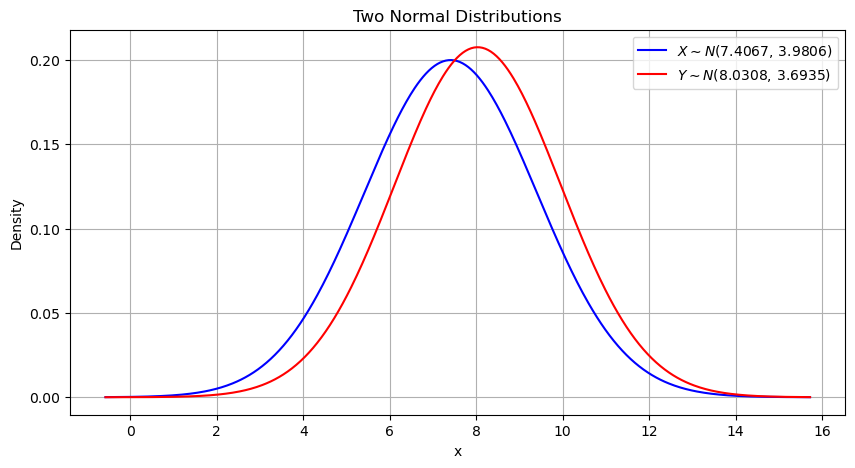

In [43]:
# Plot the distribution
# Parameters for X
mu_X = 7.4067
var_X = 3.9806
sigma_X = np.sqrt(var_X)

# Parameters for Y
mu_Y = 8.0308
var_Y = 3.6935
sigma_Y = np.sqrt(var_Y)

# Range covering both distributions
x_min = min(mu_X - 4*sigma_X, mu_Y - 4*sigma_Y)
x_max = max(mu_X + 4*sigma_X, mu_Y + 4*sigma_Y)
x = np.linspace(x_min, x_max, 500)

# Compute PDFs
pdf_X = norm.pdf(x, loc=mu_X, scale=sigma_X)
pdf_Y = norm.pdf(x, loc=mu_Y, scale=sigma_Y)

# Plot
plt.figure(figsize=(10,5))
plt.plot(x, pdf_X, label=r'$X \sim N(7.4067,\,3.9806)$', color='blue')
plt.plot(x, pdf_Y, label=r'$Y \sim N(8.0308,\,3.6935)$', color='red')

plt.title('Two Normal Distributions')
plt.xlabel('x')
plt.ylabel('Density')
plt.legend()
plt.grid(True)
plt.show()

##### **d.** Calculate the ratio of the probability that user A wrote the email over the probability that user B wrote the email

$\frac{P(A|E)}{P(B|E)} = \frac{\frac{P(E|A)P(A)}{P(E)}}{\frac{P(E|B)P(B)}{P(E)}} = \frac{P(E|A)}{P(E|B)}\frac{P(A)}{P(B)}$ 

where 

$E$: A random variable that represents the content of the text is that email

$A$, $B$: Random variables that represent the author of the text is A or B

We can further compute that

$ \frac{P(E|A)}{P(E|B)} = \frac{\binom{n}{c_1, c_2, ..., c_m}\prod_{i}p_i^{c_i}}{\binom{n}{c_1, c_2, ..., c_m}\prod_{i}q_i^{c_i}} = \frac{\prod_{i}p_i^{c_i}}{\prod_{i}q_i^{c_i}} = \frac{\prod_{i}f_{1i}^{c_i}}{\prod_{i}f_{2i}^{c_i}}$

where

c_i is the number of a particular duration shown in email.txt

$f_1$, $f_2$ are the PDFs of $X$ and $Y$, separately

To avoid the probability is too small for computer to compute, we can instead compute the log of the probability



$ log(\frac{P(E|A)}{P(E|B)}) = log(\frac{\prod_{i}f_{1i}^{c_i}}{\prod_{i}f_{2i}^{c_i}}) = \sum _ic_ilog(f_{1i}) - \sum _ic_ilog(f_{2i}) $